# 04 - Windowed features: does recent history help?

**Question:** every model so far saw one noisy cycle at a time. Does summarising the last `W` cycles
(average level and trend of each sensor) reduce error, and how long should the window be?

**Design (read first):**
- Features for a window ending at cycle *t* use only cycles *t-W+1 ... t* of **one engine** (no look-ahead,
  no mixing engines). They are summaries: last value, mean, and least-squares slope per sensor.
- Training tables keep only rows with a **complete window**. Nothing is padded or invented.
- **Fair comparison across window lengths:** a longer window drops more early cycles, so the validation rows
  would differ between runs. To compare like with like, every run below is trained and validated on the
  same rows: cycles >= 30 (the longest window tested).
- Validation is grouped by engine, as before. The test set is only touched in the final section, once.
- **Short-series rule:** the final prediction uses each test engine's last `W` cycles. The shortest FD001 test
  engine has 31 cycles, so `W <= 31` works; a longer window raises an error (no padding).

Cells marked **Your observation** are for you to complete.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent))

from src.data_loader import add_rul, load_fd001
from src.evaluation import cross_validate, mae, nasa_score, out_of_fold_predictions, rmse
from src.features import get_feature_columns
from src.models import baseline_models
from src.windows import feature_names, last_window_rows, window_table

train, test, rul_test = load_fd001()
train = add_rul(train)

CAP = 125                      # <- use the cap you decided in notebook 02
SENSORS = get_feature_columns()  # <- and the sensor set you decided in notebook 02
W_MAX = 30                     # longest window tested; every run uses cycles >= W_MAX
models = baseline_models()
print(len(SENSORS), "sensors:", SENSORS)

14 sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 2. Window-length sensitivity

In [2]:
def common_table(window, stats=("last", "mean", "slope")):
    """Windowed table restricted to the rows every window length can supply."""
    t = window_table(train, SENSORS, window=window, stats=stats)
    return t[t["cycle"] >= W_MAX].reset_index(drop=True)

rows = []
for model_name in ["linear", "hist_gradient_boosting"]:
    for w in [1, 5, 10, 20, 30]:
        tbl = common_table(w)
        cols = feature_names(SENSORS, ("last", "mean", "slope"))
        res = cross_validate(models[model_name], tbl, cols, cap=CAP)
        rows.append({"model": model_name, "window": w, "n_features": len(cols),
                     "n_rows": len(tbl), "rmse": res["rmse"].mean(), "rmse_std": res["rmse"].std(),
                     "mae": res["mae"].mean(), "nasa_score": res["nasa_score"].mean(),
                     "fit_s": res["fit_s"].mean()})
window_results = pd.DataFrame(rows).round(3)
window_results

,model,window,n_features,n_rows,rmse,rmse_std,mae,nasa_score,fit_s
0,linear,1,42,17731,21.764,1.719,17.692,33502.711,0.028
1,linear,5,42,17731,21.279,1.706,17.292,31124.051,0.028
2,linear,10,42,17731,20.600,1.430,16.778,28599.843,0.027
3,linear,20,42,17731,18.369,0.992,15.079,19829.123,0.032
4,linear,30,42,17731,16.988,0.880,13.993,16036.938,0.025
5,hist_gradient_boosting,1,42,17731,19.540,0.711,14.587,47842.790,0.517
6,hist_gradient_boosting,5,42,17731,19.440,0.658,14.319,48018.292,0.709
7,hist_gradient_boosting,10,42,17731,18.877,0.595,13.850,40803.578,0.774
8,hist_gradient_boosting,20,42,17731,15.871,0.505,11.519,19829.308,0.797
9,hist_gradient_boosting,30,42,17731,13.120,0.275,9.391,11277.846,0.783


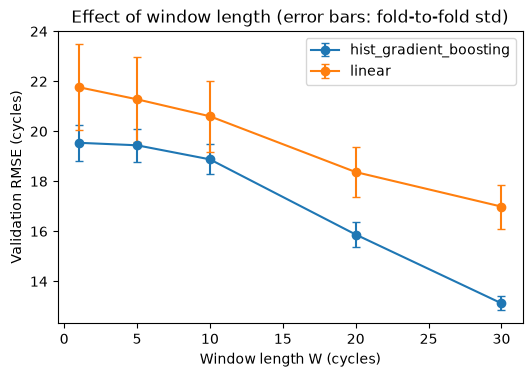

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for model_name, g in window_results.groupby("model"):
    ax.errorbar(g["window"], g["rmse"], yerr=g["rmse_std"], marker="o", capsize=3, label=model_name)
ax.set_xlabel("Window length W (cycles)")
ax.set_ylabel("Validation RMSE (cycles)")
ax.set_title("Effect of window length (error bars: fold-to-fold std)")
ax.legend()
plt.show()

**Your observation:** Does a longer window reduce error, and by how much compared with the fold-to-fold spread?
Where do the gains flatten out (diminishing returns)? Does the window help the linear model more or less than
gradient boosting? Compare `fit_s` and `n_features`: what does each extra bit of accuracy cost?
`W = 1` is the single-cycle baseline restricted to the same rows, so it is your reference point.

## 3. Which window statistics matter? (at W = 30)

Compare adding the mean and slope to the last reading.

In [4]:
stat_sets = {
    "last only": ("last",),
    "last + mean": ("last", "mean"),
    "last + slope": ("last", "slope"),
    "last + mean + slope": ("last", "mean", "slope"),
    "all four (adds std)": ("last", "mean", "std", "slope"),
}
rows = []
for label, stats in stat_sets.items():
    tbl = common_table(30, stats)
    cols = feature_names(SENSORS, stats)
    res = cross_validate(models["hist_gradient_boosting"], tbl, cols, cap=CAP)
    rows.append({"statistics": label, "n_features": len(cols), "rmse": res["rmse"].mean(),
                 "rmse_std": res["rmse"].std(), "nasa_score": res["nasa_score"].mean(),
                 "fit_s": res["fit_s"].mean()})
pd.DataFrame(rows).round(3)

,statistics,n_features,rmse,rmse_std,nasa_score,fit_s
0,last only,14,19.540,0.711,47842.790,0.346
1,last + mean,28,19.853,0.547,38426.160,0.660
2,last + slope,28,13.094,0.552,11053.569,0.631
3,last + mean + slope,42,13.120,0.275,11277.846,0.756
4,all four (adds std),56,13.319,0.459,11957.484,0.890


**Your observation:** Which statistic contributes most? Is the slope (direction of travel) adding information
beyond the average level? Is the extra `std` feature worth its cost? Judge differences against `rmse_std`.

## 4. Is the improvement consistent across folds? (paired comparison)

In [5]:
STATS = ("last", "mean", "slope")
cols1, cols30 = feature_names(SENSORS, STATS), feature_names(SENSORS, STATS)
base = cross_validate(models["hist_gradient_boosting"], common_table(1), cols1, cap=CAP)["rmse"]
win = cross_validate(models["hist_gradient_boosting"], common_table(30), cols30, cap=CAP)["rmse"]
diff = (win - base).round(2)
print("W=30 minus W=1, per fold (negative = window better):", diff.tolist())
print("mean difference:", round(diff.mean(), 2), "| folds where window is better:", int((diff < 0).sum()), "of", len(diff))

W=30 minus W=1, per fold (negative = window better): [-7.05, -5.89, -6.78, -5.96, -6.41]
mean difference: -6.42 | folds where window is better: 5 of 5


**Your observation:** Both runs use exactly the same folds and rows, so this is a paired comparison.
If the window is better in every fold, the improvement is consistent. If the signs are mixed, it is within noise.

## 5. Where does the window help? (error by RUL band)

In [6]:
bins = [-1, 25, 50, 75, 100, CAP]
labels = ["0-25", "26-50", "51-75", "76-100", f"101-{CAP}"]

def band_table(window):
    tbl = common_table(window)
    cols = feature_names(SENSORS, STATS)
    o = out_of_fold_predictions(models["hist_gradient_boosting"], tbl, cols, cap=CAP)
    band = pd.cut(o["true"], bins=bins, labels=labels)
    g = o.groupby(band, observed=True)["error"]
    return pd.DataFrame({"RMSE": g.apply(lambda e: float(np.sqrt(np.mean(e ** 2)))),
                         "bias": g.mean()}).round(2)

compare = pd.concat({"W=1": band_table(1), "W=30": band_table(30)}, axis=1)
compare

W=1          W=30      
          RMSE   bias   RMSE  bias
true                              
0-25      8.86   3.76   3.90  1.09
26-50    23.97  11.86  10.13  3.19
51-75    26.44  14.28  16.98  7.46
76-100   19.57   6.90  17.69  7.58
101-125  17.85 -12.52  12.82 -6.97

**Your observation:** In which RUL bands does the window help? Does it reduce the large late errors
(positive bias) seen in the middle of the life range? Is it more or less accurate close to failure?

## 6. Decision (fill in before touching the test set)

| Decision | Choice | Evidence |
| --- | --- | --- |
| Window length W | 30|As windows increase, the error gets lower, and so does variability regardless of the model. Validation RMSE for gradient boosting fell from 19.54 (W=1) to 13.12 (W=30). W=5 and W=10 gave little improvement relative to the fold-to-fold spread, while W=20 and W=30 gave large improvements. The curve had not flattened by W=30, which is the longest usable window (the shortest FD001 test engine has 31 cycles). Training cost stayed under one second. |
| Statistics |last + mean + slope |Slope is the statistic doing the work: last + slope alone gave RMSE 13.09, almost the same as 13.12 with the mean added. Adding the mean did not lower RMSE, but it lowered the NASA score (fewer dangerous late predictions), so I kept it. |
| Model | Histagram gradient boosting| Lower validation RMSE than linear at W=30 (13.12 vs 16.99). Chosen over random forest in notebook 02 because accuracy was similar within the fold-to-fold spread at far lower training cost.|
| Does it beat the single-cycle baseline? |Yes |Validation RMSE 13.12 with 30-cycle windows vs 19.54 with single-cycle features, a difference much larger than the fold-to-fold spread. |

## 7. Final test-set evaluation - run ONCE

Fit on all training windows, then predict each test engine from its **last W cycles**.
If you change your choices after seeing this number, the test set is no longer an unbiased check.

In [7]:
WINDOW = 30                      # <- your decision from section 6 (must be <= 31 for FD001 test)
CHOSEN_STATS = ("last", "mean", "slope")
CHOSEN_MODEL = "hist_gradient_boosting"

cols = feature_names(SENSORS, CHOSEN_STATS)
fit_tbl = window_table(train, SENSORS, window=WINDOW, stats=CHOSEN_STATS)
model = models[CHOSEN_MODEL]()
model.fit(fit_tbl[cols].to_numpy(), fit_tbl["RUL"].clip(upper=CAP).to_numpy())

test_tbl = last_window_rows(test, SENSORS, window=WINDOW, stats=CHOSEN_STATS)  # raises if any engine is too short
pred = model.predict(test_tbl[cols].to_numpy())
true = rul_test["RUL"].to_numpy()

pd.DataFrame({"windowed model": [rmse(true, pred), mae(true, pred), nasa_score(true, pred)]},
             index=["RMSE", "MAE", "NASA score"]).round(2)

,windowed model
RMSE,13.82
MAE,10.24
NASA score,268.33


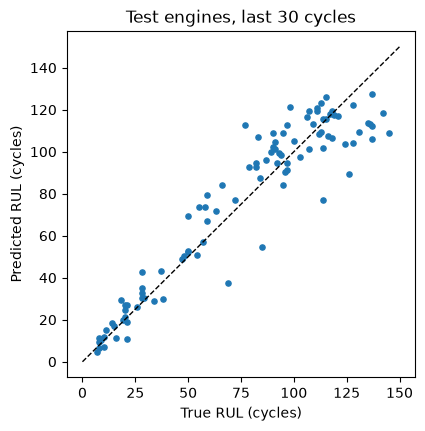

In [8]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(true, pred, s=14)
lim = [0, max(true.max(), pred.max()) + 5]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("True RUL (cycles)")
ax.set_ylabel("Predicted RUL (cycles)")
ax.set_title(f"Test engines, last {WINDOW} cycles")
plt.show()

**Your observation:** Put this beside the single-cycle test result from notebook 02. Did the window help on the
test set as it did in validation? Both are based on only 100 test engines, so how much weight can a difference of a
few cycles carry? What limitations remain (simulated data, one operating condition, one test cutoff per engine)?